In [2]:
import ot_utils
import numpy as np
import matplotlib.pyplot as plt
# import energyflow as ef
import itertools
import time
%matplotlib inline

dataset_length = 1000
num_dataset = 4
num_particles = 150
num_attr = 4

data_path = '../mini_dataset/'
file_names = ['QCD_1k.npz' ,'HToBB_1k.npz' ,'HToCC_1k.npz','HToGG_1k.npz','HToWW4Q_1k.npz','ZToQQ_1k.npz','WToQQ_1k.npz','TTBar_1k.npz']

file_names = file_names[:num_dataset]

all_events = np.zeros((num_dataset * dataset_length, num_particles, num_attr))
all_labels = np.zeros(num_dataset * dataset_length)

event_blocks = np.zeros((num_dataset, dataset_length, num_particles, num_attr))

for i, file in enumerate(file_names):
    f = np.load(data_path + file)
    
    x = f['x']
    y = f['y']
    
    all_events[i*dataset_length:(i+1)*dataset_length] = x
    all_labels[i*dataset_length:(i+1)*dataset_length] = y

# all_distance_matrix = ot_utils.calcOTDistance(all_events)
start = time.time()
eightk_distance_matrix = ot_utils.parallel_OT_square(event_set=all_events, events_per_thread=20)
end = time.time()
print(f"DONE in {end-start}")

start = time.time()
eightk_distance_matrix_2 = ot_utils.parallel_dist_mat_square(all_events, dist_func=ot_utils.get_W2_Kin, events_per_process=4096)
end = time.time()
print(f"DONE in {end-start}")
# np.save('8k_distance_matrix', eightk_distance_matrix)

DONE in 337.77953696250916
DONE in 345.71920895576477


In [2]:
assert np.allclose(eightk_distance_matrix, eightk_distance_matrix_2)
print(eightk_distance_matrix.shape)
print(eightk_distance_matrix_2)

(1000, 1000)
[[0.         0.02485649 0.13538822 ... 0.0451755  0.03518952 0.11037421]
 [0.02485649 0.         0.13536627 ... 0.04833358 0.03321655 0.1164557 ]
 [0.13538822 0.13536627 0.         ... 0.12555214 0.12723537 0.14483633]
 ...
 [0.0451755  0.04833358 0.12555214 ... 0.         0.05721264 0.10365649]
 [0.03518952 0.03321655 0.12723537 ... 0.05721264 0.         0.11173287]
 [0.11037421 0.1164557  0.14483633 ... 0.10365649 0.11173287 0.        ]]


In [2]:
# block = np.zeros((dataset_length, dataset_length))
# for i,j in itertools.combinations_with_replacement(range(num_dataset), 2):
#     if i == j:
#         block = utils.parallel_OT_square(all_events[i*1000:(i+1)*1000], events_per_thread=20)
#     else:
#         block = utils.parallel_OT_non_square(all_events[i*1000:(i+1)*1000], all_events[j*1000:(j+1)*1000], events_per_thread=20)
        
#     np.save(f'block_{i}_{j}', block)

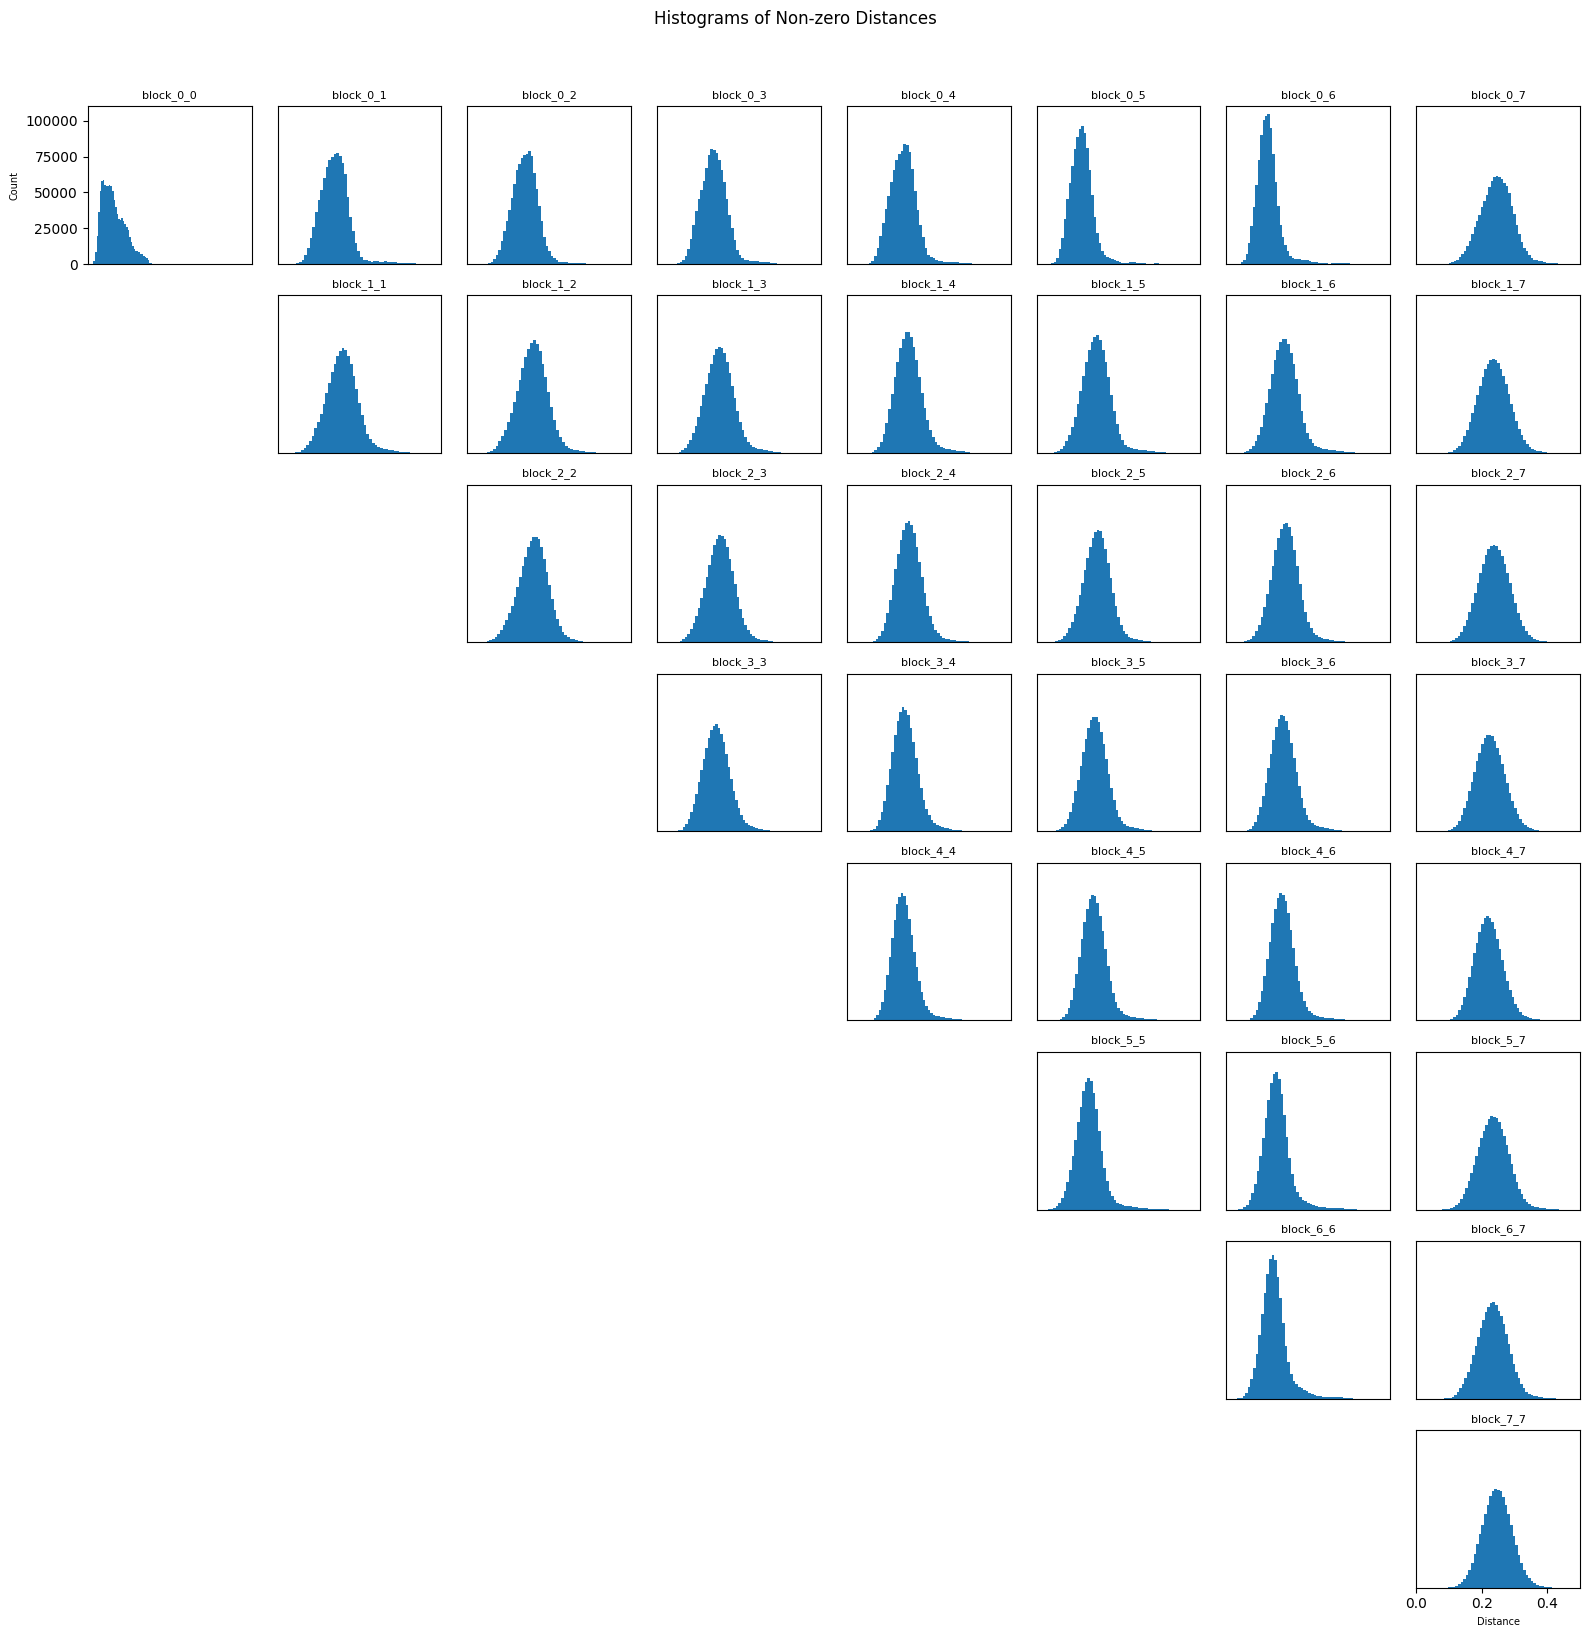

In [11]:
n = 8
fig, axes = plt.subplots(n, n, figsize=(16, 16))

for i in range(n):
    for j in range(n):
        ax = axes[i, j]
        if j >= i:
            # load the block_i_j matrix
            mat = np.load(f'block_{i}_{j}.npy')
            # extract non-zero entries
            data = mat[mat != 0]
            # plot histogram
            ax.hist(data, bins=50)
            # set x-axis limits
            ax.set_xlim(0, 0.5)
            ax.set_ylim(0, 110000)
            ax.set_title(f"block_{i}_{j}", fontsize=8)
            # only label bottom row
            if i == n - 1:
                ax.set_xlabel("Distance", fontsize=7)
            else:
                ax.set_xticks([])
            # only label first column
            if j == 0:
                ax.set_ylabel("Count", fontsize=7)
            else:
                ax.set_yticks([])
        else:
            # hide the lower-triangle axes
            ax.axis('off')

fig.suptitle("Histograms of Non-zero Distances", y=1.02)
fig.tight_layout()
plt.show()


In [4]:
# self_matrix = eightk_distance_matrix[0000:1000, 7000:8000]
# # assume distance_matrix is your (N×N) symmetric NumPy array
# # get the indices of the upper-triangle (k=1 skips the diagonal)
# # i, j = np.triu_indices(self_matrix.shape[0], k=1)

# # pick out those entries
# # unique_dists = self_matrix[i, j]
# unique_dists = self_matrix

# mask = np.where(unique_dists != 0)

# unique_dists = unique_dists[mask]
# # now plot them
# plt.figure()
# plt.hist(unique_dists, bins=50)
# plt.xlabel("Distance")
# plt.ylabel("Count")
# plt.title("Histogram of Unique Pairwise Distances")
# plt.show()